# Reprodukcja Mask R-CNN

**ADOiM, zespół J:** Damian Cienkowski, Jan Gębal, Mikołaj Tradecki

Wykorzystujemy juz wytrenowany model `mask_rcnn_R_50_FPN_3x`, ze zbioru modeli udostępnionych przez twórców oryginalnego artykułu (tzw. Model ZOO). Następnie wyerfikujemy czy na zbiorze COCO val2017 otrzymujemy te same wyniki co te zadeklarowane przez twórców modelu. Podane wyniki to: **box AP 41,0 i mask AP 37,2**.

W celu analizy porównamy tez wyniki, z wynikami z oryginalnego artykułu (He, Gkioxari, Dollár, Girshick, *Mask R-CNN*, ICCV 2017), chociaz spodziewamy się, ze nasz model będzie lepszy od tego z artykułu ze względu na mniej ograniczony zbiór treningowy.


Do **uruchomienia** notatnika uzywamy [uv](https://docs.astral.sh/uv/):
```bash
uv sync
uv run jupyter notebook K2_reprodukcja_Mask_RCNN.ipynb
```

## 0. Parametry
Stałe, z których korzysta reszta notatnika

In [ ]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
CONFIG_NAME = "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"
MODEL_ZOO_REF = {"bbox": 41.0, "segm": 37.2}          # AP [%], R50-FPN 3x
PAPER_REF = {"AP": 33.6, "AP50": 55.2, "AP75": 35.3}  # artykuł, Tab. 2a, mask AP
TOLERANCE_AP = 0.2
SEED = 42
N_VERIFY = 200
VIS_SCORE_THRESH = 0.5   # rysunki; AP liczymy przy 0,05

## 1. Środowisko

In [ ]:
import os, json, random, warnings
from IPython.display import display
import torch

warnings.filterwarnings("ignore", category=FutureWarning, module=r"torch\.jit")
warnings.filterwarnings("ignore", message=r"pkg_resources is deprecated")
import detectron2

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
PROJECT_DIR = PROJECT_DIR.resolve()
RESULTS_DIR = PROJECT_DIR / "wyniki_K2"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
os.environ["DETECTRON2_DATASETS"] = str(PROJECT_DIR / "datasets")
print(DEVICE, "| Detectron2", detectron2.__version__, "| torch", torch.__version__)


cpu | Detectron2 0.6 | torch 2.15.0


## 2. Dane: COCO val2017
Zbiór danych znajduje się w `datasets/coco/` (układ Detectron2: `val2017/` i `annotations/instances_val2017.json`). To ten sam zbiór danych, na którym testowany był oryginalny model z artykułu oraz uzywany przez nas model.

In [ ]:
COCO_ROOT = PROJECT_DIR / "datasets" / "coco"
IMG_DIR = COCO_ROOT / "val2017"
ANN_FILE = COCO_ROOT / "annotations" / "instances_val2017.json"
assert IMG_DIR.is_dir() and ANN_FILE.is_file(), f"Brak COCO val2017 w {COCO_ROOT}"

coco_json = json.loads(ANN_FILE.read_text())
n_img = len(list(IMG_DIR.glob("*.jpg")))
print(f"{n_img} obrazów, {len(coco_json['annotations'])} instancji, {len(coco_json['categories'])} klas")
assert n_img == len(coco_json["images"]) == 5000 and len(coco_json["categories"]) == 80

from detectron2.data import DatasetCatalog, MetadataCatalog
DATASET = "coco_2017_val"
META = MetadataCatalog.get(DATASET)
assert Path(META.json_file) == ANN_FILE, f"Detectron2 szuka adnotacji w {META.json_file}"

5000 obrazów, 36781 instancji, 80 klas


## 3. Model: konfiguracja i wagi
Konfigurację i URL wag podany został na stronie Detectron2. Staramy się krozystać z tej samej konfiguracji, jedyne róznice jakie mogą się pojawić to urządzenie na którym uruchamiamy model oraz biblioteka pod spodem.
Korzystamy z tego samego testowego zbioru danych co oryginał.

Tabela to hiperparametry, które sterują detekcją i treningiem tego modelu. 
Ustawiamy próg pewności `SCORE_THRESH_TEST`, po którym maska i ramka zostają odnotowane na 0.05, poniewaz takie są wymagania protokołu COCO. Na rysunkach ten próg jest wyzszy i wynosi 0.5 zeby były bardziej czytelne.

In [ ]:
import pandas as pd
from detectron2 import model_zoo
from detectron2.config import get_cfg
from detectron2.engine import DefaultPredictor
from detectron2.utils.logger import setup_logger
setup_logger()

cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file(CONFIG_NAME))
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(CONFIG_NAME)
cfg.MODEL.DEVICE = DEVICE
cfg.freeze()
predictor = DefaultPredictor(cfg)
model = predictor.model

def cfg_get(key):
    node = cfg
    for part in key.split("."):
        node = getattr(node, part)
    return node

KEY_PARAMS = [
    "INPUT.MIN_SIZE_TEST", "INPUT.MAX_SIZE_TEST",
    "MODEL.ANCHOR_GENERATOR.SIZES", "MODEL.ANCHOR_GENERATOR.ASPECT_RATIOS",
    "MODEL.RPN.PRE_NMS_TOPK_TEST", "MODEL.RPN.POST_NMS_TOPK_TEST", "MODEL.RPN.NMS_THRESH",
    "MODEL.ROI_BOX_HEAD.POOLER_TYPE", "MODEL.ROI_BOX_HEAD.POOLER_RESOLUTION", "MODEL.ROI_MASK_HEAD.POOLER_RESOLUTION",
    "MODEL.ROI_HEADS.SCORE_THRESH_TEST", "MODEL.ROI_HEADS.NMS_THRESH_TEST", "TEST.DETECTIONS_PER_IMAGE",
    "SOLVER.MAX_ITER", "SOLVER.STEPS", "INPUT.MIN_SIZE_TRAIN",
]
display(pd.DataFrame({"wartość": [str(cfg_get(k)) for k in KEY_PARAMS]}, index=KEY_PARAMS))
assert cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST == 0.05
(RESULTS_DIR / "config_uzyta.yaml").write_text(cfg.dump())

[11/11 22:56:06 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from https://dl.fbaipublicfiles.com/detectron2/COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x/137849600/model_final_f10217.pkl ...


,wartość
INPUT.MIN_SIZE_TEST,800
INPUT.MAX_SIZE_TEST,1333
MODEL.ANCHOR_GENERATOR.SIZES,"[[32], [64], [128], [256], [512]]"
MODEL.ANCHOR_GENERATOR.ASPECT_RATIOS,"[[0.5, 1.0, 2.0]]"
MODEL.RPN.PRE_NMS_TOPK_TEST,1000
MODEL.RPN.POST_NMS_TOPK_TEST,1000
MODEL.RPN.NMS_THRESH,0.7
MODEL.ROI_BOX_HEAD.POOLER_TYPE,ROIAlignV2
MODEL.ROI_BOX_HEAD.POOLER_RESOLUTION,7
MODEL.ROI_MASK_HEAD.POOLER_RESOLUTION,14


5965

## 4. Test na jednym obrazie
Na rysunku zostawiamy tylko detekcje, w których `score ≥ 0,5`, poniewaz wtedy obrazek jest bardziej czytelny.

/Users/mtradecki/Documents/ADOiM-Mask-RCNN/.venv/lib/python3.12/site-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:4209.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W1111 22:56:07.328000 9082 torch/fx/_symbolic_trace.py:57] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


000000000885.jpg: 36 detekcji, z tego 14 z score ≥ 0.5; instancji w GT: 9


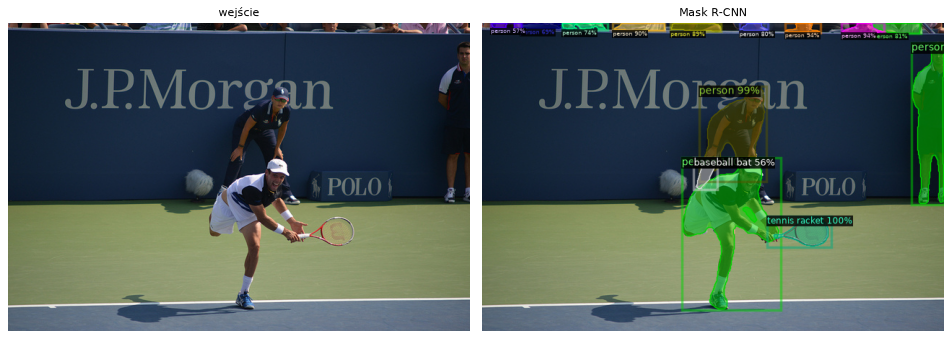

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from detectron2.utils.visualizer import Visualizer

ID2FILE = {img["id"]: img["file_name"] for img in coco_json["images"]}
ALL_IDS = sorted(ID2FILE)
N_GT = Counter(a["image_id"] for a in coco_json["annotations"] if not a["iscrowd"])

def read_image(img_id):
    return cv2.imread(str(IMG_DIR / ID2FILE[img_id]))   # BGR, tak jak oczekuje model

def confident(instances, thr=VIS_SCORE_THRESH):
    return instances[instances.scores >= thr]

def show(images, titles, save_as=None, size=4):
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size), dpi=80)
    for ax, image, title in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(image); ax.set_title(title, fontsize=10); ax.axis("off")
    plt.tight_layout()
    if save_as:
        fig.savefig(save_as, dpi=150, bbox_inches="tight")
    plt.show()

demo_id = next(i for i in ALL_IDS if 5 <= N_GT[i] <= 12)
image = read_image(demo_id)
pred = predictor(image)["instances"].to("cpu")
print(f"{ID2FILE[demo_id]}: {len(pred)} detekcji, z tego {len(confident(pred))} z score ≥ {VIS_SCORE_THRESH}; "
      f"instancji w GT: {N_GT[demo_id]}")
rgb = image[:, :, ::-1]
show([rgb, Visualizer(rgb, META).draw_instance_predictions(confident(pred)).get_image()],
     ["wejście", "Mask R-CNN"], size=6)

## 5. Pełna ewaluacja na COCO val2017
Puszczamy model przez wszystkie 5000 obrazów i liczymy AP osobno dla ramek (`bbox`) i masek (`segm`).

In [ ]:
from tqdm.auto import tqdm
from detectron2.data import build_detection_test_loader
from detectron2.evaluation import COCOEvaluator

OUT_DIR = RESULTS_DIR / "eval"
loader = build_detection_test_loader(cfg, DATASET)
evaluator = COCOEvaluator(DATASET, tasks=("bbox", "segm"), distributed=False, output_dir=str(OUT_DIR))
evaluator.reset()
with torch.no_grad():
    for inputs in tqdm(loader, desc="val2017"):
        evaluator.process(inputs, model(inputs))
metrics = {task: dict(values) for task, values in evaluator.evaluate().items()}
print(f"box AP = {metrics['bbox']['AP']:.2f}, mask AP = {metrics['segm']['AP']:.2f}")


[11/11 22:56:07 d2.data.datasets.coco]: Loaded 5000 images in COCO format from /Users/mtradecki/Documents/ADOiM-Mask-RCNN/datasets/coco/annotations/instances_val2017.json
[11/11 22:56:08 d2.data.build]: Distribution of instances among all 80 categories:
|   category    | #instances   |   category   | #instances   |   category    | #instances   |
|:-------------:|:-------------|:------------:|:-------------|:-------------:|:-------------|
|    person     | 10777        |   bicycle    | 314          |      car      | 1918         |
|  motorcycle   | 367          |   airplane   | 143          |      bus      | 283          |
|     train     | 190          |    truck     | 414          |     boat      | 424          |
| traffic light | 634          | fire hydrant | 101          |   stop sign   | 75           |
| parking meter | 60           |    bench     | 411          |     bird      | 427          |
|      cat      | 202          |     dog      | 218          |     horse     | 272      

val2017:   0%|          | 0/5000 [00:00<?, ?it/s]

/Users/mtradecki/Documents/ADOiM-Mask-RCNN/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/Users/mtradecki/Documents/ADOiM-Mask-RCNN/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/Users/mtradecki/Documents/ADOiM-Mask-RCNN/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/Users/mtradecki/Documents/ADOiM-Mask-RCNN/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/Users/mtradecki/Documents/ADOiM-Mask-RCNN/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: Fut

[11/11 23:31:09 d2.evaluation.coco_evaluation]: Preparing results for COCO format ...
[11/11 23:31:09 d2.evaluation.coco_evaluation]: Saving results to /Users/mtradecki/Documents/ADOiM-Mask-RCNN/wyniki_K2/eval/coco_instances_results.json
[11/11 23:31:09 d2.evaluation.coco_evaluation]: Evaluating predictions with unofficial COCO API...
Loading and preparing results...
DONE (t=0.04s)
creating index...
index created!
[11/11 23:31:09 d2.evaluation.fast_eval_api]: Evaluate annotation type *bbox*
[11/11 23:31:32 d2.evaluation.fast_eval_api]: COCOeval_opt.evaluate() finished in 22.55 seconds.
[11/11 23:31:32 d2.evaluation.fast_eval_api]: Accumulating evaluation results...
[11/11 23:31:32 d2.evaluation.fast_eval_api]: COCOeval_opt.accumulate() finished in 0.27 seconds.
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.410
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.615
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=10

## 6. Wyniki: box AP i mask AP
Obie liczby liczy się tak samo: średnia AP po 80 klasach i 10 progach IoU od 0,50 do 0,95. Różnica jest tylko w tym, czy dopasowanie do adnotacji mierzymy ramką, czy maską. APs, APm i APl to obiekty małe (pole maski w adnotacji < 32² px), średnie i duże (> 96² px).

,box,maska,maska − box,maska / box
AP,40.984,37.169,-3.815,0.907
AP50,61.530,58.598,-2.933,0.952
AP75,44.913,39.881,-5.033,0.888
APs,24.870,18.631,-6.239,0.749
APm,43.872,39.491,-4.381,0.900
APl,53.331,53.304,-0.027,0.999


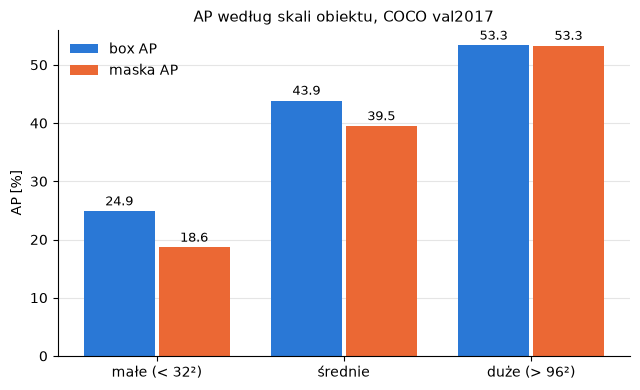

Klasy, w których maski wypadają najgorzej względem ramek:


,box AP,mask AP,maska − box
skis,24.53,3.22,-21.31
skateboard,50.46,31.49,-18.97
fork,33.53,15.28,-18.25
horse,57.37,41.55,-15.82
airplane,63.27,49.25,-14.01


Klasy, w których maski wypadają najlepiej względem ramek:


,box AP,mask AP,maska − box
refrigerator,54.86,57.00,2.14
suitcase,37.30,39.45,2.15
baseball glove,35.37,38.56,3.19
umbrella,38.06,44.65,6.59
tennis racket,46.43,53.68,7.25


In [ ]:
METRIC_KEYS = ["AP", "AP50", "AP75", "APs", "APm", "APl"]
results = pd.DataFrame({"box": [metrics["bbox"][k] for k in METRIC_KEYS],
                        "maska": [metrics["segm"][k] for k in METRIC_KEYS]}, index=METRIC_KEYS)
results["maska − box"] = results["maska"] - results["box"]
results["maska / box"] = results["maska"] / results["box"]
display(results.round(3))
results.round(3).to_csv(RESULTS_DIR / "metryki_full_val2017.csv")

# AP według skali obiektu (kolory: box = niebieski, maska = pomarańczowy)
scales = ["APs", "APm", "APl"]
x = np.arange(len(scales))
fig, ax = plt.subplots(figsize=(6.5, 4))
for offset, column, color in ((-0.2, "box", "#2a78d6"), (0.2, "maska", "#eb6834")):
    bars = ax.bar(x + offset, results.loc[scales, column], 0.38, color=color, label=f"{column} AP")
    ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=9)
ax.set_xticks(x, ["małe (< 32²)", "średnie", "duże (> 96²)"])
ax.set_ylabel("AP [%]")
ax.set_title("AP według skali obiektu, COCO val2017", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5"); ax.set_axisbelow(True)
ax.legend(frameon=False)
plt.tight_layout(); fig.savefig(RESULTS_DIR / "ap_wg_skali.png", dpi=150); plt.show()

# AP dla poszczególnych klas
per_class = pd.DataFrame({
    "box AP": {k[3:]: v for k, v in metrics["bbox"].items() if k.startswith("AP-")},
    "mask AP": {k[3:]: v for k, v in metrics["segm"].items() if k.startswith("AP-")},
})
per_class["maska − box"] = per_class["mask AP"] - per_class["box AP"]
per_class.round(3).to_csv(RESULTS_DIR / "ap_per_klasa_full_val2017.csv")
ranked = per_class.sort_values("maska − box").round(2)
print("Klasy, w których maski wypadają najgorzej względem ramek:"); display(ranked.head(5))
print("Klasy, w których maski wypadają najlepiej względem ramek:"); display(ranked.tail(5))

## 7. Porównanie z oceną modelu z Detectron 2 i z artykułem
Właściwy test, po którym potwierdzimy czy udało się zreprodukować wyniki to porównanie z oceną modelu na stronie Detectron 2. Różnica powinna zmieścić się w ±0,2 pkt AP i moze wynikać ze sposobu w jaki nowsze wersje bilbiotek wykonują obliczenia.

Model w artykule był uczony na innym zbiorze, stąd porównanie słuzy jedynie jako ciekawostka.

In [ ]:
vs_zoo = pd.DataFrame({
    "nasz wynik": [metrics["bbox"]["AP"], metrics["segm"]["AP"]],
    "Model Zoo": [MODEL_ZOO_REF["bbox"], MODEL_ZOO_REF["segm"]],
}, index=["box AP", "mask AP"])
vs_zoo["Δ"] = vs_zoo["nasz wynik"] - vs_zoo["Model Zoo"]
vs_zoo["zreprodukowano"] = vs_zoo["Δ"].abs() <= TOLERANCE_AP
print("Porównanie z Detectron2 Model Zoo (R50-FPN 3x):"); display(vs_zoo.round(2))

vs_paper = pd.DataFrame({
    "nasz wynik": [metrics["segm"][k] for k in PAPER_REF],
    "artykuł (Tab. 2a)": list(PAPER_REF.values()),
}, index=[f"mask {k}" for k in PAPER_REF])
vs_paper["Δ"] = vs_paper["nasz wynik"] - vs_paper["artykuł (Tab. 2a)"]
print("Porównanie z artykułem (R-50-FPN, minival):"); display(vs_paper.round(2))

pd.concat({"Model Zoo": vs_zoo, "artykuł": vs_paper}).round(3).to_csv(RESULTS_DIR / "porownanie_z_referencja.csv")

Porównanie z Detectron2 Model Zoo (R50-FPN 3x):


,nasz wynik,Model Zoo,Δ,zreprodukowano
box AP,40.98,41.0,-0.02,True
mask AP,37.17,37.2,-0.03,True


Porównanie z artykułem (R-50-FPN, minival):


,nasz wynik,artykuł (Tab. 2a),Δ
mask AP,37.17,33.6,3.57
mask AP50,58.60,55.2,3.40
mask AP75,39.88,35.3,4.58


## 8. Skąd się biorą różnice

### Nasz wynik a model referencyjny.
Wynik naszego modelu wyniósł **box AP 40.98 i mask AP 37.17**, podczas gdy ten sam model według autorów w Model Zoo osiągnął **41.0 i 37.2**. Róznica wynosi zaledwie 0.02 i 0.03 pkt i wynika najpewniej z zaokrąglenia. Udało się więc odtworzyć wyniki.

### Model Zoo a artykuł
Nasza mask AP jest o **3,6 pkt wyższa** niż wynik R-50-FPN w artykule (37,17 wobec 33,6; dla AP50 +3,4, dla AP75 +4,6). Róznica wynika najpewniej z innych danych treningowych oraz roznicy w wykorzystanych bibliotekach.

| Element | Artykuł (2017) | Detectron2 Model Zoo (R50-FPN 3x) |
|---|---|---|
| implementacja | Detectron (Caffe2) | Detectron2 (PyTorch) |
| długość treningu | 160k iteracji, lr 0,02, spadek 10× przy 120k (sekcja 3.1) | 270k iteracji, spadki przy 210k i 250k (`SOLVER.MAX_ITER`, `SOLVER.STEPS`) |
| sposób treningu | etapowy: najpierw RPN, potem Mask R-CNN (Dodatek B) | end-to-end, RPN i głowy razem |
| skala obrazów w treningu | stała, 800 px | losowa, 640–800 px (`INPUT.MIN_SIZE_TRAIN`) |
| próg NMS | 0,3 (Dodatek B) | 0,5 (`MODEL.ROI_HEADS.NMS_THRESH_TEST`) |
| RoIAlign | wersja z artykułu | `ROIAlignV2` z korektą przesunięcia o pół piksela |
| zbiór testowy | minival (5000 obrazów z val2014) | val2017 (w praktyce te same obrazy) |

### Ramki a maski
Maski są średnio o **3,8 pkt AP gorsze od ramek**, ale to nie jest równy spadek na wszystkich obiektach:

| Obiekty | box AP | mask AP | maska / box |
|---|---|---|---|
| małe | 24,9 | 18,6 | 0,75 |
| średnie | 43,9 | 39,5 | 0,90 |
| duże | 53,3 | 53,3 | 1,00 |

Dla dużych obiektów maska jest tak samo dobra jak ramka, a dla małych traci jedną czwartą AP. Jest to zgodne z budową modelu: gałąź maski przewiduje maskę 28×28 wewnątrz ramki, więc przy małym obiekcie brakuje rozdzielczości na dokładny kształt. Różnica rośnie też z wymaganą dokładnością dopasowania: przy IoU 0,5 maski tracą 2,9 pkt, przy IoU 0,75 już 5,0 pkt.

Najsłabiej maski wypadają dla obiektów cienkich i wydłużonych: narty (box 24,5 → maska 3,2), deskorolka (50,5 → 31,5), widelec (33,5 → 15,3). Lepsze od ramek są dla obiektów zwartych, np. rakieta tenisowa (46,4 → 53,7) i parasol (38,1 → 44,7).

## 9. Ramki i maski osobno
AP z poprzednich sekcji to jedna liczba na cały zbiór. Tu patrzymy na instancje. Na 200 losowych obrazach, dla każdej adnotacji (bez `iscrowd`) bierzemy predykcję tej samej klasy z `score ≥ 0,5` o największym IoU ramki i dla niej liczymy też IoU maski. Jeśli IoU ramki < 0,5, instancję traktujemy jako pominiętą.  

`iscrowd` to flaga w zbiorze danych, która oznacza, ze annotacja zaznacza obszar, w którym gęsto umieszczone są obiekty tego samego typu.

Obok siebie są adnotacje, same ramki i same maski — widać, że model zgłasza te same obiekty, tylko kształt bywa gorszy niż ramka. PNG-i są w `wyniki_K2/`.

loading annotations into memory...
Done (t=0.16s)
creating index...
index created!


weryfikacja:   0%|          | 0/200 [00:00<?, ?it/s]

1275 instancji na 200 obrazach; średnie IoU liczone dla instancji wykrytych


,instancje,pominięte [%],śr. IoU ramki,śr. IoU maski,maska − ramka
skala,,,,,
małe,487,51.951,0.770,0.711,-0.059
średnie,418,30.861,0.832,0.783,-0.050
duże,370,14.865,0.866,0.836,-0.031


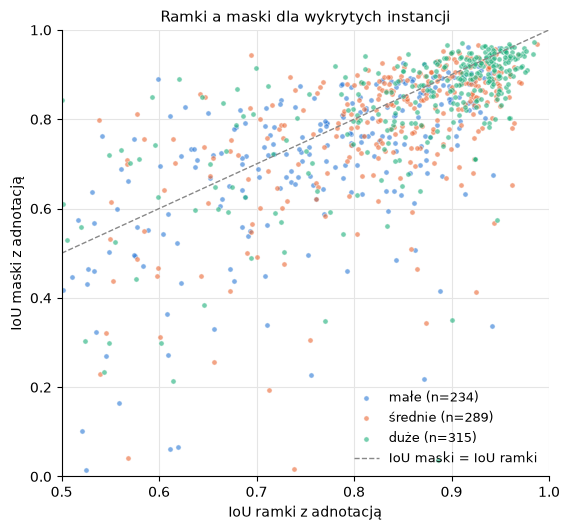

In [ ]:
from tqdm.auto import tqdm
from pycocotools.coco import COCO
from pycocotools import mask as mask_utils
from detectron2.structures import Instances

coco_gt = COCO(str(ANN_FILE))

TO_COCO_ID = {contiguous: coco_id for coco_id, contiguous in META.thing_dataset_id_to_contiguous_id.items()}
CATEGORY = {c["id"]: c["name"] for c in coco_json["categories"]}

def size_group(area):
    return "małe" if area < 32 ** 2 else ("średnie" if area <= 96 ** 2 else "duże")

verify_ids = sorted(random.Random(SEED).sample(ALL_IDS, N_VERIFY))
predictions, records = {}, []
for img_id in tqdm(verify_ids, desc="weryfikacja"):
    pred = confident(predictor(read_image(img_id))["instances"].to("cpu"))
    predictions[img_id] = pred
    if len(pred):
        boxes = pred.pred_boxes.tensor.numpy().astype(np.float64)
        boxes[:, 2:] -= boxes[:, :2]                                   # XYXY → XYWH, jak w COCO
        masks = mask_utils.encode(np.asfortranarray(pred.pred_masks.numpy().transpose(1, 2, 0).astype(np.uint8)))
        classes = np.array([TO_COCO_ID[int(c)] for c in pred.pred_classes])
    for ann in coco_gt.loadAnns(coco_gt.getAnnIds(imgIds=img_id, iscrowd=False)):
        box_iou = mask_iou = 0.0
        same_class = np.where(classes == ann["category_id"])[0] if len(pred) else []
        if len(same_class):
            box_ious = mask_utils.iou(boxes[same_class], np.array([ann["bbox"]], dtype=np.float64), [0])[:, 0]
            best = same_class[int(np.argmax(box_ious))]
            box_iou = float(box_ious.max())
            mask_iou = float(mask_utils.iou([masks[best]], [coco_gt.annToRLE(ann)], [0])[0, 0])
        records.append({"image_id": img_id, "klasa": CATEGORY[ann["category_id"]], "pole": ann["area"],
                        "skala": size_group(ann["area"]), "box_iou": box_iou, "mask_iou": mask_iou})

verify = pd.DataFrame(records)
verify["wykryta"] = verify["box_iou"] >= 0.5
verify.to_csv(RESULTS_DIR / "weryfikacja_ramek_i_masek.csv", index=False)

found = verify[verify["wykryta"]]
summary = pd.DataFrame({
    "instancje": verify.groupby("skala").size(),
    "pominięte [%]": 100 * (1 - verify.groupby("skala")["wykryta"].mean()),
    "śr. IoU ramki": found.groupby("skala")["box_iou"].mean(),
    "śr. IoU maski": found.groupby("skala")["mask_iou"].mean(),
}).reindex(["małe", "średnie", "duże"])
summary["maska − ramka"] = summary["śr. IoU maski"] - summary["śr. IoU ramki"]
print(f"{len(verify)} instancji na {N_VERIFY} obrazach; średnie IoU liczone dla instancji wykrytych")
display(summary.round(3))
summary.round(4).to_csv(RESULTS_DIR / "weryfikacja_podsumowanie.csv")

# IoU ramki a IoU maski tej samej predykcji
fig, ax = plt.subplots(figsize=(5.8, 5.4))
for scale, color in (("małe", "#2a78d6"), ("średnie", "#eb6834"), ("duże", "#1baf7a")):
    part = found[found["skala"] == scale]
    ax.scatter(part["box_iou"], part["mask_iou"], s=14, alpha=0.6, color=color,
               edgecolors="white", linewidths=0.5, label=f"{scale} (n={len(part)})")
ax.plot([0.5, 1], [0.5, 1], color="#888888", linewidth=1, linestyle="--", label="IoU maski = IoU ramki")
ax.set_xlim(0.5, 1); ax.set_ylim(0, 1)
ax.set_xlabel("IoU ramki z adnotacją"); ax.set_ylabel("IoU maski z adnotacją")
ax.set_title("Ramki a maski dla wykrytych instancji", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(color="#e5e5e5"); ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=9, loc="lower right")
plt.tight_layout(); fig.savefig(RESULTS_DIR / "ramki_vs_maski_iou.png", dpi=150); plt.show()

[11/11 23:33:03 d2.data.datasets.coco]: Loaded 5000 images in COCO format from /Users/mtradecki/Documents/ADOiM-Mask-RCNN/datasets/coco/annotations/instances_val2017.json


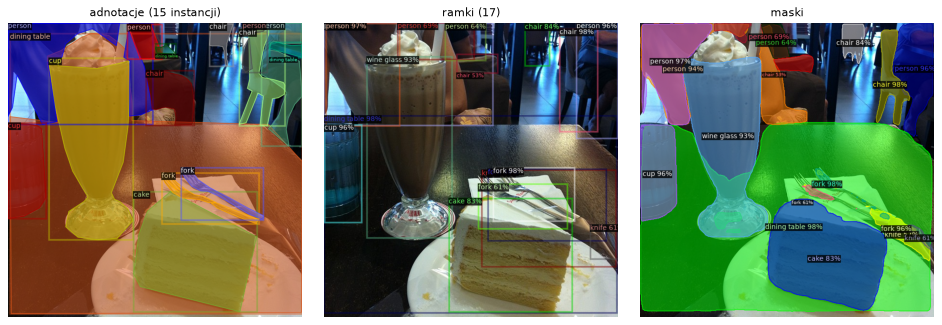

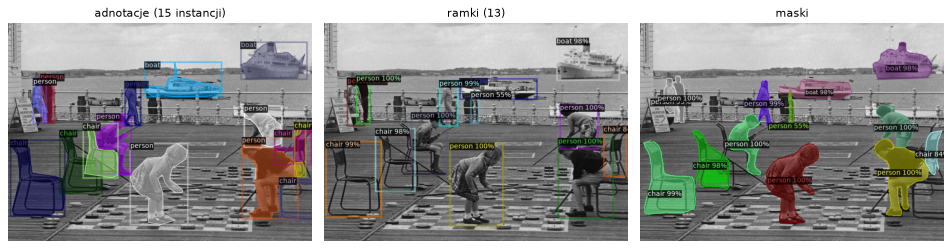

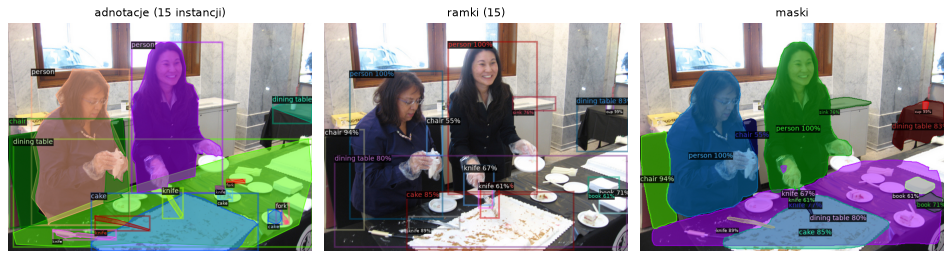

In [ ]:
# Adnotacje | same ramki | same maski, dla obrazów z kilkoma instancjami
gt_dicts = {d["image_id"]: d for d in DatasetCatalog.get(DATASET)}
examples = sorted((i for i in verify_ids if 4 <= N_GT[i] <= 15), key=lambda i: -N_GT[i])[:3]
for img_id in examples:
    rgb = read_image(img_id)[:, :, ::-1]
    pred = predictions[img_id]
    boxes_only = Instances(pred.image_size, pred_boxes=pred.pred_boxes, scores=pred.scores, pred_classes=pred.pred_classes)
    masks_only = Instances(pred.image_size, pred_masks=pred.pred_masks, scores=pred.scores, pred_classes=pred.pred_classes)
    show([Visualizer(rgb, META).draw_dataset_dict(gt_dicts[img_id]).get_image(),
          Visualizer(rgb, META).draw_instance_predictions(boxes_only).get_image(),
          Visualizer(rgb, META).draw_instance_predictions(masks_only).get_image()],
         [f"adnotacje ({N_GT[img_id]} instancji)", f"ramki ({len(pred)})", "maski"],
         save_as=RESULTS_DIR / f"ramki_i_maski_{img_id}.png")

To samo, co było widać w AP, wraca na instancjach. Przy `score ≥ 0,5` model pomija 52% małych obiektów, 31% średnich i 15% dużych. Tam, gdzie coś znajdzie, IoU maski jest niższe niż IoU ramki, i to bardziej przy małych obiektach (0,06 / 0,05 / 0,03). Maska dziedziczy błąd położenia ramki i dokłada własny błąd kształtu. Na rysunkach ramki i maski dotyczą tych samych detekcji. W zatłoczonych kadrach najgorzej idzie małe, cienkie i stykające się rzeczy — sztućce, naczynia na stole.

## 10. Wnioski
1. **Checkpoint udało się odtworzyć.** Box AP 40,98 i mask AP 37,17 różnią się od 41,0 i 37,2 o −0,02 i −0,03 pkt, w granicach ±0,2.
2. **Wyższy wynik niż w artykule (+3,6 mask AP) wynika z innych danych i parametrów treningu**, nie z błędu reprodukcji: dłuższy, end-to-end, z losową skalą i ROIAlignV2. Autorzy sami pokazują w Dodatku B, że te zmiany podnoszą AP.
3. **Maski odstają od ramek głównie na małych i cienkich obiektach** (dla małych ok. 75% AP ramek, dla dużych praktycznie 100%). Gałąź maski rysuje 28×28 wewnątrz ramki — przy małym obiekcie na kształt po prostu brakuje pikseli.

W `wyniki_K2/` są konfiguracja, metryki i rysunki.